# Hands-on 6
## Clasificadores basados en distancia: k Nearest Neighbors (kNN)
### Diagnóstico de cáncer de mama (benigno vs maligno) con Python y scikit-learn

Materia: Machine Learning

Autora: Paola Michelle Ambriz Soto

Objetivo: mostrar paso a paso cómo implementar la técnica kNN con scikit-learn, siguiendo las etapas del pipeline de Machine Learning, desde la recolección de datos hasta la evaluación del modelo.

Dataset: Breast Cancer Prediction Dataset (Kaggle), https://www.kaggle.com/datasets/merishnasuwal/breast-cancer-prediction-dataset

Contenido del notebook:

1. Fundamentos teóricos de la técnica kNN
2. Abstracción matemática
3. Pipeline de Machine Learning
   - 3.1 Definición del problema
   - 3.2 Recolección de datos
   - 3.3 Descripción y análisis del dataset
   - 3.4 Scatter plot
   - 3.5 Preparación de los datos
   - 3.6 El algoritmo a mano (una predicción paso a paso)
   - 3.7 Selección del modelo: elegir el valor de k
   - 3.8 Entrenamiento
   - 3.9 Predicción
   - 3.10 Evaluación (métricas)
   - 3.11 Visualización de la frontera de decisión
   - 3.12 Conclusiones

# 1. Fundamentos teóricos de la técnica kNN

## 1.1 La idea en una frase

Para decidir a qué clase pertenece un dato nuevo, kNN busca los k datos conocidos que más se le parecen y elige la clase que más se repite entre ellos.

Es la versión matemática del refrán "dime con quién andas y te diré quién eres".

## 1.2 Un ejemplo de la vida diaria

Imagina que te mudas a una colonia nueva y quieres saber si es tranquila o ruidosa. Le preguntas a tus 5 vecinos más cercanos. Si 4 dicen que es tranquila y 1 dice que es ruidosa, concluyes que es tranquila. Eso es kNN con k = 5:

- Los vecinos son los datos de entrenamiento (ya sabemos su clase).
- La colonia es el dato nuevo que queremos clasificar.
- Preguntar a los 5 más cercanos es buscar los k vecinos.
- Quedarte con la respuesta más repetida es la votación por mayoría.

En este notebook los "vecinos" son pacientes cuyo tumor ya fue diagnosticado como benigno o maligno, y el dato nuevo es un paciente cuyo diagnóstico queremos predecir a partir de las medidas del tumor.

## 1.3 Dónde encaja kNN dentro del Machine Learning

| Característica | En kNN |
|---|---|
| Tipo de aprendizaje | Supervisado: los datos de entrenamiento ya traen su etiqueta (benigno o maligno) |
| Tarea | Clasificación: predecir una categoría. (kNN también sirve para regresión, pero aquí lo usamos para clasificar) |
| Familia | Clasificador basado en distancia: la similitud entre dos datos se mide como qué tan cerca están |

## 1.4 Dos rasgos que lo hacen distinto a otras técnicas

Aprendizaje perezoso (lazy learning). En las técnicas que vimos antes (regresión, perceptrón, SVM) el entrenamiento consiste en ajustar números (pesos) hasta encontrar una recta o un hiperplano. kNN no hace eso: en el entrenamiento solo memoriza los datos. Todo el trabajo ocurre hasta el momento de predecir.

No paramétrico. kNN no supone que los datos sigan una forma determinada y no tiene coeficientes que aprender. Lo único que decide quien lo usa es el valor de k, que es un hiperparámetro (un ajuste que se elige antes de entrenar, no se aprende de los datos).

Consecuencia: en el perceptrón y la SVM la frontera entre clases es una recta o un hiperplano explícito. En kNN la frontera no existe como fórmula; aparece sola a partir de la posición de los datos y puede tener formas muy irregulares.

## 1.5 Cómo funciona, paso a paso

1. Se elige el valor de k (cuántos vecinos se consultan).
2. Llega un dato nuevo cuya clase se desconoce.
3. Se calcula la distancia entre el dato nuevo y cada dato de entrenamiento.
4. Se ordenan las distancias y se toman los k datos más cercanos.
5. Se cuentan las clases de esos k vecinos y gana la que más se repite.

## 1.6 ¿Qué pasa según el valor de k?

| Valor de k | Efecto | Problema |
|---|---|---|
| Muy pequeño (por ejemplo 1) | El modelo copia a su único vecino, incluso si es un dato raro o con ruido | Sobreajuste (overfitting): memoriza en lugar de generalizar |
| Muy grande | Se promedian vecinos que ya no son realmente parecidos | Subajuste (underfitting): el modelo se vuelve demasiado simple |
| Intermedio | Equilibrio entre ambos | Se busca con validación cruzada (sección 3.7) |

## 1.7 Ventajas y desventajas

| Ventajas | Desventajas |
|---|---|
| Muy fácil de entender e implementar | Predecir es lento con muchos datos, porque hay que medir la distancia contra todos |
| No requiere fase de entrenamiento | Necesita guardar todo el dataset en memoria |
| Funciona con fronteras de decisión no lineales | Es sensible a la escala de las variables, por lo que hay que escalarlas |
| Solo tiene un hiperparámetro importante (k) | Pierde precisión cuando hay muchas variables (maldición de la dimensionalidad) |

# 2. Abstracción matemática

## 2.1 Notación

Tenemos un conjunto de entrenamiento con N ejemplos:

$$D = \{(\mathbf{x}_1, y_1), (\mathbf{x}_2, y_2), \dots, (\mathbf{x}_N, y_N)\}$$

| Símbolo | Significado | En este dataset |
|---|---|---|
| $\mathbf{x}_i$ | Vector de características del ejemplo i (sus medidas) | Radio, textura, perímetro, área y suavidad del tumor |
| $d$ | Número de características | 5 |
| $y_i$ | Etiqueta (clase) del ejemplo i | 0 = maligno, 1 = benigno |
| $N$ | Número de ejemplos de entrenamiento | 455 (el 80 % de 569) |
| $\mathbf{x}$ | Dato nuevo que queremos clasificar | Un paciente nuevo |
| $k$ | Número de vecinos que se consultan | Se elige en la sección 3.7 |

## 2.2 Medir "qué tan parecidos" son dos datos: la distancia

Cada paciente es un punto en un espacio de d dimensiones (aquí 5). Dos pacientes parecidos son dos puntos cercanos. La distancia de Minkowski generaliza varias distancias conocidas:

$$d(\mathbf{a}, \mathbf{b}) = \left( \sum_{j=1}^{d} |a_j - b_j|^p \right)^{1/p}$$

Dos casos particulares muy usados:

Distancia Manhattan (p = 1): suma de las diferencias absolutas, como caminar por las calles de una cuadrícula.

$$d_1(\mathbf{a}, \mathbf{b}) = \sum_{j=1}^{d} |a_j - b_j|$$

Distancia Euclidiana (p = 2): la distancia en línea recta, la que se usa por defecto en scikit-learn.

$$d_2(\mathbf{a}, \mathbf{b}) = \sqrt{\sum_{j=1}^{d} (a_j - b_j)^2}$$

Ejemplo con dos características: si a = (1, 2) y b = (4, 6), entonces la distancia euclidiana es raíz de (3 al cuadrado + 4 al cuadrado) = raíz de 25 = 5.

## 2.3 Los vecinos más cercanos

Para un dato nuevo x se calcula su distancia a todos los ejemplos de entrenamiento, y se define el conjunto de los k más cercanos:

$$N_k(\mathbf{x}) = \{ i \;:\; \mathbf{x}_i \text{ está entre los } k \text{ ejemplos con menor } d(\mathbf{x}, \mathbf{x}_i) \}$$

## 2.4 Regla de decisión (votación por mayoría)

$$\hat{y}(\mathbf{x}) = \underset{c}{\arg\max} \sum_{i \in N_k(\mathbf{x})} \mathbb{1}[\, y_i = c \,]$$

Cómo leerla:

- La función indicadora $\mathbb{1}[y_i = c]$ vale 1 si el vecino i pertenece a la clase c y 0 si no. Es decir, sirve para contar.
- La suma cuenta cuántos de los k vecinos son de la clase c.
- $\arg\max$ elige la clase c que obtuvo más votos.

También se puede estimar una probabilidad dividiendo entre k:

$$P(y = c \mid \mathbf{x}) \approx \frac{1}{k} \sum_{i \in N_k(\mathbf{x})} \mathbb{1}[\, y_i = c \,]$$

Ejemplo: con k = 5, si 4 vecinos son benignos y 1 es maligno, la proporción estimada de benigno es 4/5 = 0.8 y el modelo predice benigno.

Aclaración importante: este número es una proporción de votos de los vecinos, no una probabilidad clínica calibrada. Si el resultado es 1.0 para maligno, significa que todos los k vecinos eran malignos, no que exista certeza médica del 100 %.

## 2.5 Variante: voto ponderado por distancia

Una opción es que los vecinos más cercanos pesen más en la votación, con pesos $w_i = 1 / d(\mathbf{x}, \mathbf{x}_i)$. En scikit-learn se activa con el parámetro weights igual a "distance". En este notebook usamos el voto uniforme (todos valen lo mismo), que es el comportamiento por defecto.

Detalle: si un vecino está exactamente a distancia cero, la división 1/0 no está definida. scikit-learn lo contempla de forma especial: en ese caso solo votan los vecinos con distancia cero.

## 2.6 Escalamiento de las variables

Como kNN se basa en distancias, una variable con valores muy grandes domina el cálculo. En este dataset el área del tumor ronda los cientos (por ejemplo 650), mientras que la suavidad ronda 0.1. Sin escalar, la distancia casi solo dependería del área. Por eso se estandariza cada variable:

$$z = \frac{x - \mu}{\sigma}$$

donde $\mu$ es la media y $\sigma$ la desviación estándar de esa variable calculadas con los datos de entrenamiento. Después de estandarizar, cada variable tiene media 0 y desviación estándar 1, es decir, escalas y varianzas comparables. Ojo: esto no garantiza que todas las variables sean igual de importantes para predecir, ni elimina la redundancia entre variables muy parecidas.

## 2.7 Costo computacional

| Fase | Costo aproximado |
|---|---|
| Entrenamiento | Casi nulo: solo se almacenan los datos |
| Predicción de un dato nuevo | Del orden de $N \cdot d$ operaciones, porque se mide la distancia contra los N ejemplos |

Por eso kNN es cómodo con datasets pequeños (como este, de 569 filas) y se vuelve lento con millones de datos.

# 3. Pipeline de Machine Learning

Un pipeline es la secuencia de etapas que seguimos para construir un modelo, de los datos crudos a la evaluación:

Problema → Datos → Análisis → Scatter plot → Preparación → Modelo (elegir k) → Entrenamiento → Predicción → Evaluación

En cada etapa primero se explica qué se hace y por qué, y luego se muestra el código con sus líneas comentadas.

## 3.1 Definición del problema

Pregunta que queremos responder: dadas las medidas de un tumor de mama (radio, textura, perímetro, área y suavidad), ¿el tumor es benigno o maligno?

| Elemento | Descripción |
|---|---|
| Tipo de problema | Clasificación binaria (dos clases posibles) |
| Variable objetivo (lo que se predice) | diagnosis: 0 = maligno, 1 = benigno |
| Variables de entrada | mean_radius, mean_texture, mean_perimeter, mean_area, mean_smoothness |
| Técnica | kNN (k vecinos más cercanos) |
| Métrica principal | Exactitud (accuracy) para comparar valores de k. Se complementa con la matriz de confusión y con el recall de la clase maligno, porque dejar escapar un tumor maligno es el error más grave |

Ojo con la clase positiva: aquí 0 = maligno, pero en muchas funciones de scikit-learn la clase positiva por defecto es la 1 (benigno). Como nos interesa detectar los tumores malignos, en las métricas de malignidad hay que indicar explícitamente pos_label = 0.

Nota: este es un ejercicio académico. Un modelo así no sustituye un diagnóstico médico.

## 3.2 Recolección de datos

Esta etapa consiste en reunir los datos y cargarlos en Python. Primero importamos las librerías que vamos a usar:

| Librería | Para qué sirve |
|---|---|
| numpy | Cálculos numéricos con arreglos |
| pandas | Manejar tablas de datos (DataFrame) |
| matplotlib y seaborn | Hacer gráficas |
| scikit-learn | Dividir datos, escalar, modelo kNN y métricas |

Después leemos el archivo CSV con el dataset. El archivo Breast_cancer_data.csv está en la carpeta de este hands-on en el repositorio de GitHub; el código lo descarga desde ahí. Si no se puede descargar, busca el archivo en la carpeta local (en Colab, súbelo desde el panel de archivos de la izquierda).

In [1]:
import numpy as np                                   # numpy: cálculos numéricos con arreglos
import pandas as pd                                  # pandas: manejo de tablas de datos (DataFrame)
import matplotlib.pyplot as plt                      # matplotlib: gráficas básicas
import seaborn as sns                                # seaborn: gráficas estadísticas más vistosas
from matplotlib.colors import ListedColormap         # para definir los colores de la frontera de decisión
from sklearn.model_selection import train_test_split, cross_val_score  # dividir datos y validación cruzada
from sklearn.preprocessing import StandardScaler     # escalador: estandariza cada variable (media 0, desv. 1)
from sklearn.neighbors import KNeighborsClassifier   # el clasificador kNN de scikit-learn
from sklearn.pipeline import Pipeline               # Pipeline: encadena escalador + modelo para evitar fuga de datos
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             recall_score, precision_score, make_scorer)  # métricas de evaluación
from matplotlib.patches import Patch                 # para armar leyendas manuales en la frontera de decisión
import os                                            # os: para comprobar si un archivo existe en la carpeta local

sns.set_theme(style="whitegrid")                     # estilo visual limpio para todas las gráficas

In [2]:
# Dirección del archivo CSV en el repositorio público de GitHub (cambia el usuario o la carpeta si es necesario)
url_csv = "https://raw.githubusercontent.com/Michelleas31/Hands-on-6/refs/heads/main/Breast_cancer_data.csv"

try:                                                 # intentamos primero descargar el archivo desde GitHub
    df = pd.read_csv(url_csv)                        # read_csv lee el archivo CSV y lo convierte en un DataFrame
except OSError as error:                             # error de conexión o archivo no encontrado en GitHub (URLError y HTTPError son OSError)
    print("No se pudo descargar el CSV desde GitHub:", error)  # avisamos qué pasó, en lugar de ocultar el error
    if not os.path.exists("Breast_cancer_data.csv"): # revisamos que el archivo local de respaldo exista
        raise FileNotFoundError("Sube Breast_cancer_data.csv a la carpeta del notebook o corrige url_csv")  # mensaje claro si no está
    df = pd.read_csv("Breast_cancer_data.csv")       # leemos el archivo desde la carpeta local

# Agregamos una columna con el nombre de la clase, solo para que las gráficas sean más fáciles de leer
df["clase"] = df["diagnosis"].map({0: "Maligno", 1: "Benigno"})  # map traduce cada número a su nombre

## 3.3 Descripción y análisis del dataset

Antes de construir cualquier modelo hay que conocer los datos. Revisamos:

- Cuántas filas y columnas hay, y de qué tipo es cada columna.
- Si hay valores faltantes (nulos), porque kNN no los acepta.
- Las estadísticas básicas (media, mínimo, máximo...) de cada variable.
- Si las clases están balanceadas, es decir, si hay cantidades parecidas de benignos y malignos.
- Cómo se distribuye cada variable según la clase, y qué tan relacionadas están entre sí.

Descripción de las columnas del dataset:

| Columna | Significado |
|---|---|
| mean_radius | Radio promedio del tumor (distancia del centro al borde) |
| mean_texture | Textura promedio (variación de los tonos de gris en la imagen) |
| mean_perimeter | Perímetro promedio del tumor |
| mean_area | Área promedio del tumor |
| mean_smoothness | Suavidad promedio (qué tan regular es el contorno) |
| diagnosis | Diagnóstico: 0 = maligno, 1 = benigno |

In [3]:
print(df.head())                                     # head muestra las primeras 5 filas para ver cómo luce la tabla
print("\nFilas y columnas:", df.shape)               # shape devuelve (número de filas, número de columnas)

   mean_radius  mean_texture  mean_perimeter  mean_area  mean_smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   diagnosis    clase  
0          0  Maligno  
1          0  Maligno  
2          0  Maligno  
3          0  Maligno  
4          0  Maligno  

Filas y columnas: (569, 7)


In [4]:
df.info()                                            # info muestra el tipo de dato y cuántos valores no nulos tiene cada columna

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   mean_radius      569 non-null    float64
 1   mean_texture     569 non-null    float64
 2   mean_perimeter   569 non-null    float64
 3   mean_area        569 non-null    float64
 4   mean_smoothness  569 non-null    float64
 5   diagnosis        569 non-null    int64  
 6   clase            569 non-null    object 
dtypes: float64(5), int64(1), object(1)
memory usage: 31.2+ KB


In [5]:
print(df.describe().round(3))                        # describe calcula media, desviación, mínimo, cuartiles y máximo por columna

       mean_radius  mean_texture  mean_perimeter  mean_area  mean_smoothness  \
count      569.000       569.000         569.000    569.000          569.000   
mean        14.127        19.290          91.969    654.889            0.096   
std          3.524         4.301          24.299    351.914            0.014   
min          6.981         9.710          43.790    143.500            0.053   
25%         11.700        16.170          75.170    420.300            0.086   
50%         13.370        18.840          86.240    551.100            0.096   
75%         15.780        21.800         104.100    782.700            0.105   
max         28.110        39.280         188.500   2501.000            0.163   

       diagnosis  
count    569.000  
mean       0.627  
std        0.484  
min        0.000  
25%        0.000  
50%        1.000  
75%        1.000  
max        1.000  


In [6]:
print(df.isnull().sum())                             # cuenta los valores nulos (faltantes) en cada columna

mean_radius        0
mean_texture       0
mean_perimeter     0
mean_area          0
mean_smoothness    0
diagnosis          0
clase              0
dtype: int64


clase
Benigno    357
Maligno    212
Name: count, dtype: int64

Proporción por clase (%):
clase
Benigno    62.7
Maligno    37.3
Name: proportion, dtype: float64


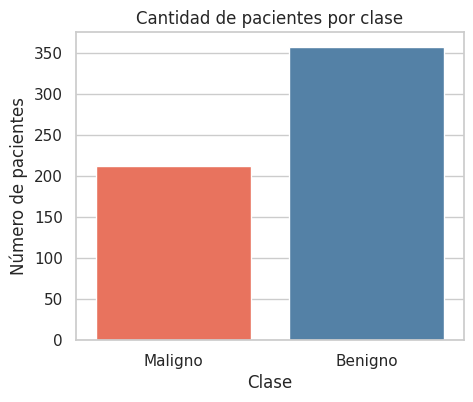

In [7]:
print(df["clase"].value_counts())                    # cuenta cuántos pacientes hay en cada clase
print("\nProporción por clase (%):")                 # texto para identificar la salida siguiente
print((df["clase"].value_counts(normalize=True) * 100).round(1))  # normalize=True convierte los conteos en proporciones

plt.figure(figsize=(5, 4))                           # crea una figura de 5x4 pulgadas
sns.countplot(data=df, x="clase", hue="clase", palette={"Maligno": "tomato", "Benigno": "steelblue"}, legend=False)  # barras por clase
plt.title("Cantidad de pacientes por clase")         # título de la gráfica
plt.xlabel("Clase")                                  # etiqueta del eje x
plt.ylabel("Número de pacientes")                    # etiqueta del eje y
plt.show()                                           # muestra la gráfica

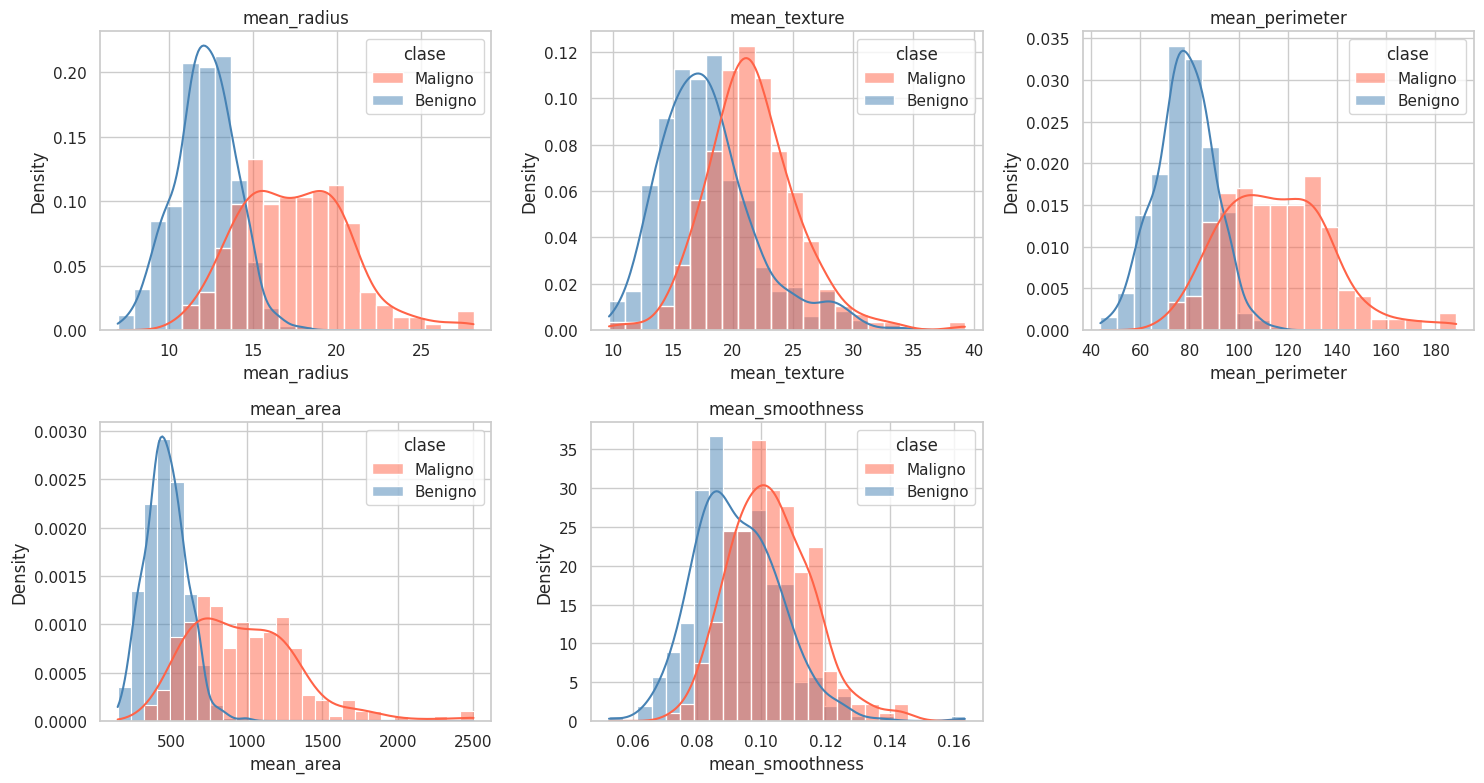

In [8]:
variables = ["mean_radius", "mean_texture", "mean_perimeter", "mean_area", "mean_smoothness"]  # lista con las 5 variables de entrada

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))      # rejilla de 2 filas x 3 columnas de gráficas
ejes = ejes.flatten()                                # convierte la rejilla en una lista simple para recorrerla con un for
for i, var in enumerate(variables):                  # recorre cada variable con su posición i
    sns.histplot(data=df, x=var, hue="clase", kde=True, ax=ejes[i], stat="density", common_norm=False,
                 palette={"Maligno": "tomato", "Benigno": "steelblue"})  # histograma por clase en densidad: la altura no depende de cuántos pacientes hay por clase
    ejes[i].set_title(var)                           # el título de cada gráfica es el nombre de la variable
ejes[5].axis("off")                                  # la sexta casilla sobra, así que se oculta
plt.tight_layout()                                   # acomoda las gráficas para que no se encimen
plt.show()                                           # muestra la figura completa

Cómo leer estos histogramas: están en densidad (cada clase se normaliza por separado), así que la altura de las barras no depende de que haya más pacientes benignos que malignos. Si las curvas de las dos clases casi no se traslapan, esa variable separa bien a benignos de malignos. En este dataset, variables como el radio, el perímetro y el área muestran una separación clara (los tumores malignos tienden a ser más grandes), mientras que la suavidad se traslapa bastante más.

Ahora veamos la correlación entre variables. Un valor cercano a 1 significa que dos variables suben y bajan juntas; cercano a 0, que no se relacionan.

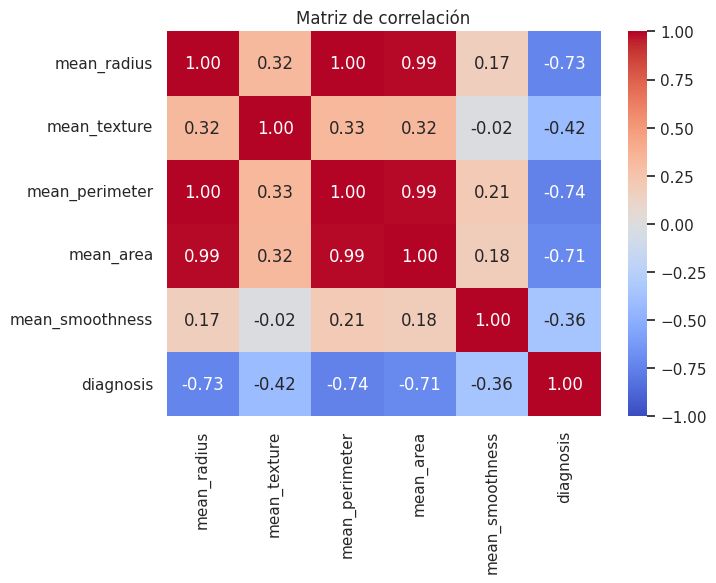

In [9]:
correlacion = df[variables + ["diagnosis"]].corr()   # corr calcula la correlación de cada par de columnas numéricas

plt.figure(figsize=(7, 5))                           # figura de 7x5 pulgadas
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)  # mapa de calor con el valor escrito en cada celda
plt.title("Matriz de correlación")                   # título de la gráfica
plt.show()                                           # muestra la gráfica

Observaciones: el radio, el perímetro y el área están casi perfectamente correlacionados (tiene sentido: si el tumor es más grande, las tres medidas crecen). Además, todas se relacionan de forma negativa con diagnosis, lo que significa que a mayor tamaño es más probable la clase 0 (maligno).

Implicación para kNN: tres de las cinco variables (radio, perímetro y área) contienen casi la misma información sobre el tamaño del tumor. Estandarizar iguala las escalas, pero no elimina esa redundancia, así que el tamaño tiene una influencia conjunta mayor en las distancias que la textura o la suavidad.

## 3.4 Scatter plot

Un diagrama de dispersión (scatter plot) dibuja cada paciente como un punto, usando dos variables como ejes y un color para la clase. Es la mejor forma de ver la idea de kNN: si los puntos de la misma clase se agrupan, entonces los vecinos cercanos de un punto nuevo suelen compartir su clase.

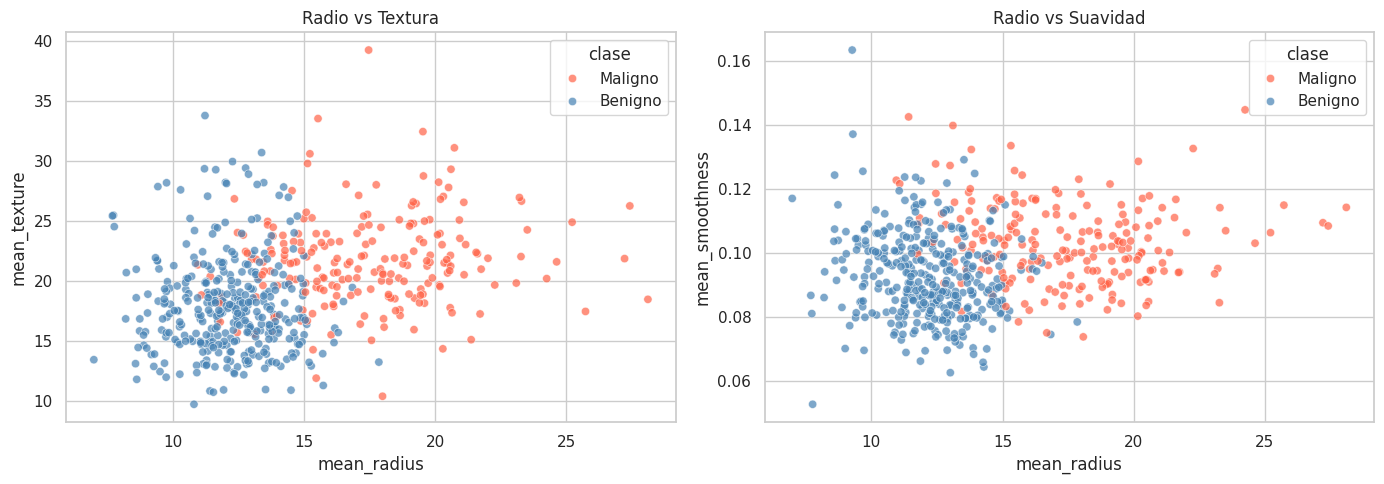

In [10]:
colores = {"Maligno": "tomato", "Benigno": "steelblue"}  # diccionario: qué color le toca a cada clase

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))      # dos gráficas lado a lado

sns.scatterplot(data=df, x="mean_radius", y="mean_texture", hue="clase",
                palette=colores, alpha=0.7, ax=ejes[0])  # radio vs textura, coloreado por clase (alpha da transparencia)
ejes[0].set_title("Radio vs Textura")                # título de la primera gráfica

sns.scatterplot(data=df, x="mean_radius", y="mean_smoothness", hue="clase",
                palette=colores, alpha=0.7, ax=ejes[1])  # radio vs suavidad, coloreado por clase
ejes[1].set_title("Radio vs Suavidad")               # título de la segunda gráfica

plt.tight_layout()                                   # acomoda las gráficas
plt.show()                                           # muestra la figura

Interpretación: en la gráfica de radio contra textura los puntos rojos (malignos) se concentran hacia la derecha (radios grandes) y los azules (benignos) hacia la izquierda. Hay una zona de traslape en medio, y justo ahí es donde kNN puede equivocarse. Los puntos que están claramente dentro de su grupo se clasifican casi sin error.

## 3.5 Preparación de los datos

Esta etapa deja los datos listos para el modelo. Tiene tres pasos:

Paso 1: separar las variables de entrada (X) de la variable objetivo (y).

Paso 2: dividir en entrenamiento y prueba. Se usa 80 % para que el modelo "aprenda" (en kNN, para que memorice) y 20 % para evaluarlo con pacientes que no ha visto, como un examen sorpresa. Los parámetros importantes son:

| Parámetro | Qué hace |
|---|---|
| test_size = 0.2 | El 20 % de los datos se reserva para prueba |
| random_state = 42 | Fija el azar para que el resultado sea reproducible |
| stratify = y | Mantiene la misma proporción de benignos y malignos en ambos grupos |

Paso 3: escalar las variables. Como kNN usa distancias, primero revisamos qué tan distintas son las escalas y luego estandarizamos. Importante: el escalador se ajusta (fit) solo con los datos de entrenamiento y después se aplica (transform) a los de prueba. Si se ajustara con todos los datos, información del examen se colaría al entrenamiento (fuga de datos o data leakage).

In [11]:
X = df[variables]                                    # X: tabla con solo las 5 variables de entrada
y = df["diagnosis"]                                  # y: la variable que queremos predecir (0 o 1)

X_train, X_test, y_train, y_test = train_test_split(  # divide los datos en entrenamiento y prueba
    X, y,                                            # variables de entrada y variable objetivo
    test_size=0.2,                                   # 20 % para prueba
    random_state=42,                                 # semilla para que siempre salga la misma división
    stratify=y                                       # conserva la proporción de clases en ambos grupos
)

print("Pacientes de entrenamiento:", X_train.shape[0])  # cuántas filas quedaron para entrenar
print("Pacientes de prueba:", X_test.shape[0])         # cuántas filas quedaron para probar

Pacientes de entrenamiento: 455
Pacientes de prueba: 114


In [12]:
# Revisamos la escala de cada variable (mínimo y máximo) en los datos de entrenamiento
print(X_train.describe().loc[["min", "max"]].round(3))  # fíjate en la diferencia entre mean_area y mean_smoothness

     mean_radius  mean_texture  mean_perimeter  mean_area  mean_smoothness
min        6.981          9.71           43.79      143.5            0.063
max       28.110         39.28          188.50     2499.0            0.145


Observa que mean_area llega a miles y mean_smoothness no pasa de 0.2. Sin escalar, la distancia euclidiana dependería casi únicamente del área. Estandarizamos para que todas las variables tengan escalas comparables.

In [13]:
escalador = StandardScaler()                         # crea el escalador (aún no ha visto ningún dato)
X_train_esc = escalador.fit_transform(X_train)       # fit calcula media y desviación del entrenamiento; transform los aplica
X_test_esc = escalador.transform(X_test)             # a prueba solo se le aplica transform, con la media y desviación del entrenamiento

print("Media de cada variable (entrenamiento):", np.round(X_train_esc.mean(axis=0), 2))  # debe quedar cerca de 0
print("Desv. estándar de cada variable (entrenamiento):", np.round(X_train_esc.std(axis=0), 2))  # debe quedar cerca de 1

Media de cada variable (entrenamiento): [-0.  0. -0. -0.  0.]
Desv. estándar de cada variable (entrenamiento): [1. 1. 1. 1. 1.]


## 3.6 El algoritmo a mano (una predicción paso a paso)

Antes de usar scikit-learn, hagamos lo que hace kNN por dentro con un solo paciente de prueba, usando k = 5. Así se ve que no hay magia: es medir distancias, ordenarlas y contar votos.

In [14]:
k_demo = 5                                           # número de vecinos que vamos a consultar en este ejemplo
paciente = X_test_esc[0]                             # tomamos el primer paciente de prueba (ya escalado)

# Paso 1: distancia euclidiana del paciente contra TODOS los pacientes de entrenamiento
distancias = np.sqrt(((X_train_esc - paciente) ** 2).sum(axis=1))  # resta, eleva al cuadrado, suma por fila y saca raíz

# Paso 2: posiciones de los k pacientes con menor distancia
vecinos = np.argsort(distancias)[:k_demo]            # argsort ordena de menor a mayor y devuelve las posiciones; tomamos las k primeras

# Paso 3: clase y distancia de cada vecino
clases_vecinos = y_train.values[vecinos]             # etiquetas (0 o 1) de los k vecinos
print("Distancias a los 5 vecinos:", np.round(distancias[vecinos], 3))  # qué tan lejos está cada vecino
print("Clases de los 5 vecinos (0 = maligno, 1 = benigno):", clases_vecinos)  # su diagnóstico

# Paso 4: votación por mayoría
prediccion_manual = np.bincount(clases_vecinos).argmax()  # bincount cuenta los votos por clase; argmax elige la que más tiene
print("Predicción a mano:", prediccion_manual, "->", "Benigno" if prediccion_manual == 1 else "Maligno")  # resultado
print("Diagnóstico real:", y_test.iloc[0], "->", "Benigno" if y_test.iloc[0] == 1 else "Maligno")  # lo comparamos con la realidad

Distancias a los 5 vecinos: [0.475 0.485 0.603 0.682 0.747]
Clases de los 5 vecinos (0 = maligno, 1 = benigno): [0 0 0 0 0]
Predicción a mano: 0 -> Maligno
Diagnóstico real: 0 -> Maligno


## 3.7 Selección del modelo: elegir el valor de k

Esta es la decisión más importante de kNN. Como vimos en la sección 1.6, un k muy chico sobreajusta y uno muy grande subajusta. Para elegirlo probamos varios valores y comparamos su exactitud con validación cruzada (cross-validation):

1. Los datos de entrenamiento se parten en 5 bloques (cv = 5).
2. Se entrena con 4 bloques y se evalúa con el bloque restante.
3. Se repite 5 veces cambiando el bloque de evaluación y se promedian las 5 exactitudes.

Así elegimos k sin tocar los datos de prueba, que se guardan para la evaluación final. Probamos solo valores impares de k para evitar empates en la votación cuando hay dos clases.

Cuidado con la fuga de datos (data leakage) dentro de la validación cruzada. Si escaláramos todo el entrenamiento antes de partirlo en bloques, la media y la desviación estándar ya habrían "visto" los datos del bloque que se usa para evaluar. Para evitarlo usamos un Pipeline: una cadena de pasos (primero el escalador, luego kNN) que scikit-learn aplica por separado en cada bloque. Así, en cada vuelta el escalador se ajusta únicamente con los 4 bloques de entrenamiento. Por eso aquí la validación cruzada recibe X_train sin escalar.

Además de la exactitud, mostramos la desviación estándar entre los 5 bloques (barras de error en la gráfica) para ver qué tan estable es cada k, y el recall de la clase maligno para el k elegido.

In [15]:
valores_k = list(range(1, 32, 2))                    # probaremos k = 1, 3, 5, ..., 31 (solo impares)
exactitud_cv = []                                    # lista donde guardaremos la exactitud promedio de cada k
desviacion_cv = []                                   # lista donde guardaremos la desviación estándar entre los 5 bloques

for k in valores_k:                                  # recorre cada valor de k
    modelo_k = Pipeline([                            # cadena de pasos que se aplica por separado en cada bloque
        ("escalador", StandardScaler()),             # paso 1: estandarizar (se ajusta solo con el entrenamiento de cada bloque)
        ("knn", KNeighborsClassifier(n_neighbors=k)) # paso 2: clasificador kNN con ese k
    ])
    puntajes = cross_val_score(modelo_k, X_train, y_train, cv=5, scoring="accuracy")  # exactitud en cada uno de los 5 bloques (con X_train sin escalar)
    exactitud_cv.append(puntajes.mean())             # guarda el promedio de los 5 bloques
    desviacion_cv.append(puntajes.std())             # guarda cuánto varían los 5 bloques entre sí

mejor_k = valores_k[int(np.argmax(exactitud_cv))]    # argmax da la posición de la mayor exactitud; con ella obtenemos el k
print("Mejor valor de k:", mejor_k)                  # mostramos el k ganador
print("Exactitud promedio con ese k:", round(max(exactitud_cv), 4))  # y su exactitud en validación cruzada

# Recall de la clase maligno (0) para el k elegido: qué porcentaje de malignos detecta en validación cruzada
modelo_mejor = Pipeline([("escalador", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=mejor_k))])  # mismo pipeline con el mejor k
recall_cv = cross_val_score(modelo_mejor, X_train, y_train, cv=5,
                            scoring=make_scorer(recall_score, pos_label=0))  # pos_label=0 indica que "positivo" es maligno
print("Recall de maligno con ese k (validación cruzada):", round(recall_cv.mean(), 4))  # promedio de los 5 bloques

Mejor valor de k: 21
Exactitud promedio con ese k: 0.9429
Recall de maligno con ese k (validación cruzada): 0.8765


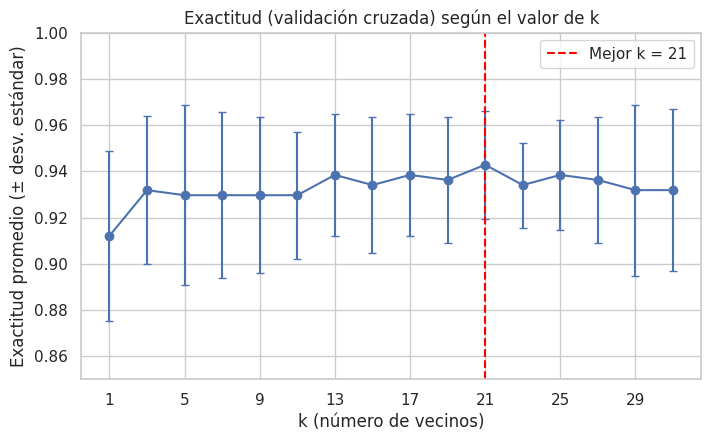

In [16]:
plt.figure(figsize=(8, 4.5))                         # figura de 8x4.5 pulgadas
plt.errorbar(valores_k, exactitud_cv, yerr=desviacion_cv, marker="o", capsize=3)  # línea con barras de error (± desviación estándar)
plt.axvline(mejor_k, color="red", linestyle="--", label=f"Mejor k = {mejor_k}")  # línea vertical roja en el mejor k
plt.title("Exactitud (validación cruzada) según el valor de k")  # título
plt.xlabel("k (número de vecinos)")                  # etiqueta del eje x
plt.ylabel("Exactitud promedio (± desv. estándar)")  # etiqueta del eje y
plt.ylim(0.85, 1.0)                                  # eje y acotado para ver las diferencias (son de pocos puntos porcentuales)
plt.xticks(valores_k[::2])                           # marcas del eje x cada dos valores para que no se amontonen
plt.legend()                                         # muestra la leyenda
plt.show()                                           # muestra la gráfica

## 3.8 Entrenamiento

Con el k elegido, creamos el modelo y lo "entrenamos". En kNN, entrenar (fit) solo significa guardar los datos de entrenamiento y sus etiquetas en una estructura que permita buscar vecinos rápido. No se calculan pesos ni se optimiza nada.

Parámetros principales de KNeighborsClassifier:

| Parámetro | Qué hace | Valor que usamos |
|---|---|---|
| n_neighbors | Número de vecinos k | El mejor k de la sección anterior |
| weights | Cómo votan los vecinos: uniform (todos igual) o distance (los cercanos pesan más) | uniform (el valor por defecto) |
| metric y p | Tipo de distancia. Con minkowski y p = 2 equivale a la euclidiana | minkowski, p = 2 |

In [17]:
knn = KNeighborsClassifier(                          # creamos el clasificador kNN
    n_neighbors=mejor_k,                             # k elegido con validación cruzada
    weights="uniform",                               # todos los vecinos votan con el mismo peso
    metric="minkowski",                              # familia de distancias de Minkowski
    p=2                                              # p = 2 equivale a la distancia euclidiana
)

knn.fit(X_train_esc, y_train)                        # "entrena": guarda los pacientes de entrenamiento y sus etiquetas
print("Modelo entrenado con k =", knn.n_neighbors)   # confirmamos el k con el que quedó el modelo

Modelo entrenado con k = 21


## 3.9 Predicción

Ahora usamos el modelo con los pacientes de prueba, que no vio durante el entrenamiento. Por cada paciente, scikit-learn hace lo mismo que hicimos a mano en la sección 3.6: busca los k vecinos más cercanos y vota.

Además de la clase, podemos pedir la proporción de votos (qué fracción de los k vecinos votó por cada clase) y ver quiénes fueron los vecinos. Recuerda que es una estimación basada en los vecinos, no una probabilidad clínica calibrada: un resultado de [1, 0] significa que los k vecinos votaron maligno, no que haya certeza médica.

In [18]:
y_pred = knn.predict(X_test_esc)                     # predice la clase de todos los pacientes de prueba

comparacion = pd.DataFrame({                         # tabla para comparar predicción contra realidad
    "Real": y_test.values[:10],                      # diagnóstico real de los primeros 10 pacientes de prueba
    "Predicho": y_pred[:10]                          # diagnóstico predicho para esos mismos pacientes
})
print(comparacion.T)                                 # .T pone la tabla en horizontal para verla más compacta

          0  1  2  3  4  5  6  7  8  9
Real      0  1  0  1  0  1  1  0  0  0
Predicho  0  1  0  0  0  1  1  0  0  0


In [19]:
proporciones = knn.predict_proba(X_test_esc[:1])     # proporción de votos por clase para el primer paciente de prueba
print("Proporción de votos [maligno, benigno]:", proporciones[0])  # cada valor es la fracción de los k vecinos de esa clase

distancias_sk, vecinos_sk = knn.kneighbors(X_test_esc[:1])  # kneighbors devuelve distancias y posiciones de los vecinos
print("Distancias a sus vecinos:", np.round(distancias_sk[0], 3))  # qué tan lejos está cada vecino
print("Clases de sus vecinos:", y_train.values[vecinos_sk[0]])     # diagnóstico de cada vecino

Proporción de votos [maligno, benigno]: [1. 0.]
Distancias a sus vecinos: [0.475 0.485 0.603 0.682 0.747 0.9   0.937 0.992 1.008 1.073 1.074 1.154
 1.191 1.216 1.426 1.435 1.438 1.476 1.484 1.538 1.56 ]
Clases de sus vecinos: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


## 3.10 Evaluación (métricas)

Comparamos las predicciones contra los diagnósticos reales de los pacientes de prueba. La herramienta base es la matriz de confusión, que cuenta los aciertos y los errores de cada tipo. Para leerla, tomamos "maligno" como la clase que más nos interesa detectar:

| | Predicho maligno | Predicho benigno |
|---|---|---|
| Real maligno | Verdadero positivo (VP): maligno detectado | Falso negativo (FN): maligno que se nos escapó |
| Real benigno | Falso positivo (FP): falsa alarma | Verdadero negativo (VN): benigno correcto |

Métricas que salen de esa tabla:

$$\text{Exactitud (accuracy)} = \frac{VP + VN}{VP + VN + FP + FN}$$

$$\text{Precisión} = \frac{VP}{VP + FP} \qquad \text{Recall (sensibilidad)} = \frac{VP}{VP + FN} \qquad F1 = 2 \cdot \frac{\text{Precisión} \cdot \text{Recall}}{\text{Precisión} + \text{Recall}}$$

| Métrica | Pregunta que responde |
|---|---|
| Exactitud | De todos los pacientes, ¿qué porcentaje se clasificó bien? |
| Precisión | De los que el modelo llamó malignos, ¿cuántos realmente lo eran? |
| Recall | De los tumores que realmente eran malignos, ¿cuántos detectó el modelo? |
| F1 | Un solo número que equilibra precisión y recall |

En un problema médico el error más grave es el falso negativo (decir "benigno" cuando es maligno), por eso el recall de la clase maligno merece atención especial.

Ojo con la clase positiva: en este dataset maligno es 0, pero scikit-learn suele tomar 1 como clase positiva por defecto. Por eso, al calcular recall o precisión de malignidad con funciones sueltas, se indica pos_label = 0. El classification_report no tiene ese problema porque muestra las dos clases por separado.

In [20]:
exactitud = accuracy_score(y_test, y_pred)           # porcentaje de predicciones correctas en el conjunto de prueba
print("Exactitud (accuracy):", round(exactitud, 4))  # mostramos la exactitud

Exactitud (accuracy): 0.9123


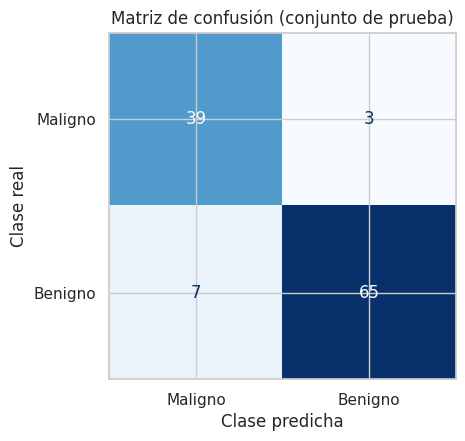

Malignos clasificados como benignos (falsos negativos): 3
Benignos clasificados como malignos (falsas alarmas): 7


In [21]:
cm = confusion_matrix(y_test, y_pred)                # matriz de confusión; filas = real, columnas = predicho (orden: 0, 1)

fig, eje = plt.subplots(figsize=(5.5, 4.5))          # figura donde dibujaremos la matriz
ConfusionMatrixDisplay(cm, display_labels=["Maligno", "Benigno"]).plot(ax=eje, cmap="Blues", colorbar=False)  # dibuja la matriz con nombres de clase
eje.set_title("Matriz de confusión (conjunto de prueba)")  # título
eje.set_xlabel("Clase predicha")                     # etiqueta del eje x
eje.set_ylabel("Clase real")                         # etiqueta del eje y
plt.show()                                           # muestra la gráfica

print("Malignos clasificados como benignos (falsos negativos):", cm[0, 1])  # el error más grave en este contexto
print("Benignos clasificados como malignos (falsas alarmas):", cm[1, 0])    # el error menos grave

In [22]:
print(classification_report(                         # reporte con precisión, recall y F1 por cada clase
    y_test, y_pred,                                  # diagnósticos reales y predichos
    target_names=["Maligno", "Benigno"]              # nombres de las clases en orden 0, 1
))

              precision    recall  f1-score   support

     Maligno       0.85      0.93      0.89        42
     Benigno       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



In [23]:
recall_maligno = recall_score(y_test, y_pred, pos_label=0)        # recall de maligno: pos_label=0 indica que la clase "positiva" es maligno
precision_maligno = precision_score(y_test, y_pred, pos_label=0)  # precisión de maligno, con el mismo criterio
print("Recall de maligno:", round(recall_maligno, 4))             # qué porcentaje de los malignos reales detectó el modelo
print("Precisión de maligno:", round(precision_maligno, 4))       # qué porcentaje de las alertas de maligno fueron correctas
print("Malignos que el modelo no detectó:", cm[0, 1], "de", cm[0].sum())  # falsos negativos sobre el total de malignos reales

Recall de maligno: 0.9286
Precisión de maligno: 0.8478
Malignos que el modelo no detectó: 3 de 42


Cómo leer el reporte: cada renglón corresponde a una clase. En el renglón Maligno, precision responde qué tan confiables son las alertas de cáncer del modelo, y recall indica qué porcentaje de los tumores malignos reales logró detectar. La columna support es cuántos pacientes de prueba hay de esa clase.

### Experimento extra: ¿qué pasa si no escalamos?

Para comprobar que el escalado importa, entrenamos otro kNN con los datos originales (sin estandarizar) y comparamos la exactitud.

In [24]:
knn_sin_escalar = KNeighborsClassifier(n_neighbors=mejor_k)  # mismo k, pero lo entrenaremos con datos sin escalar
knn_sin_escalar.fit(X_train, y_train)                # entrenamos con las variables originales
y_pred_sin = knn_sin_escalar.predict(X_test)         # predecimos con las variables originales de prueba

print("Exactitud CON escalado:", round(accuracy_score(y_test, y_pred), 4))      # resultado del modelo principal
print("Exactitud SIN escalado:", round(accuracy_score(y_test, y_pred_sin), 4))  # resultado del experimento

Exactitud CON escalado: 0.9123
Exactitud SIN escalado: 0.8947


Si la exactitud sin escalar sale igual o menor, se confirma la idea de la sección 2.6: sin estandarizar, el área domina la distancia y el resto de las variables casi no aportan. Con otros datos y otras divisiones el efecto puede ser más grande o más pequeño, pero estandarizar es siempre una buena práctica en kNN.

## 3.11 Visualización de la frontera de decisión

Con 5 variables no podemos dibujar el espacio completo, así que para ver cómo "piensa" kNN entrenamos un modelo auxiliar con solo 2 variables (radio y textura). Como este modelo usa otras variables, el k de la sección 3.7 no tiene por qué servirle: elegimos un k propio con validación cruzada (otra vez con Pipeline) usando solo sus datos de entrenamiento. Se colorea cada punto del plano según la clase que predeciría kNN allí. Se observará que la frontera no es una recta como en el perceptrón o en la SVM lineal, sino una zona irregular que se adapta a la posición de los datos.

k elegido para el modelo de 2 variables: 11


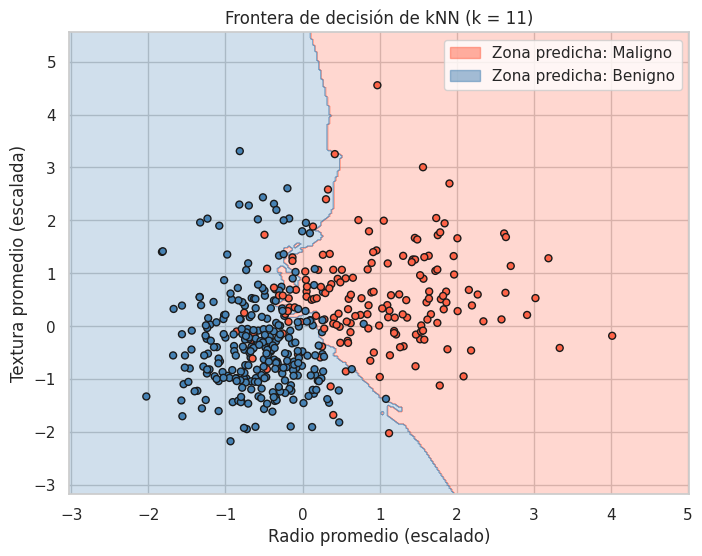

Exactitud del modelo con solo 2 variables: 0.8684


In [25]:
X2 = df[["mean_radius", "mean_texture"]]             # nos quedamos solo con dos variables para poder graficar en 2D
X2_train, X2_test, y2_train, y2_test = train_test_split(  # misma división que antes (mismo random_state y stratify)
    X2, y, test_size=0.2, random_state=42, stratify=y
)

esc2 = StandardScaler()                              # nuevo escalador para estas dos variables
X2_train_esc = esc2.fit_transform(X2_train)          # ajusta y escala el entrenamiento
X2_test_esc = esc2.transform(X2_test)                # escala la prueba con los valores del entrenamiento

# Elegimos un k propio para el modelo de 2 variables (validación cruzada con Pipeline, solo con X2_train)
exactitud_2d = []                                    # exactitud promedio de cada k
for k in valores_k:                                  # reutilizamos la misma lista de k impares
    pipe2 = Pipeline([("escalador", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k))])  # escalado dentro de cada bloque
    exactitud_2d.append(cross_val_score(pipe2, X2_train, y2_train, cv=5, scoring="accuracy").mean())  # promedio de los 5 bloques
k_2d = valores_k[int(np.argmax(exactitud_2d))]       # k con mayor exactitud para el modelo de 2 variables
print("k elegido para el modelo de 2 variables:", k_2d)  # mostramos el k ganador

knn2 = KNeighborsClassifier(n_neighbors=k_2d)        # kNN auxiliar con su propio k
knn2.fit(X2_train_esc, y2_train)                     # lo entrenamos con las dos variables

# Creamos una malla de puntos que cubre todo el plano para predecir la clase en cada uno
x_min, x_max = X2_train_esc[:, 0].min() - 1, X2_train_esc[:, 0].max() + 1  # límites del eje x con un margen
y_min, y_max = X2_train_esc[:, 1].min() - 1, X2_train_esc[:, 1].max() + 1  # límites del eje y con un margen
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))  # malla de 300x300 puntos
zona = knn2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)  # predice cada punto de la malla y recupera la forma 2D

plt.figure(figsize=(8, 6))                           # figura de 8x6 pulgadas
plt.contourf(xx, yy, zona, alpha=0.25, cmap=ListedColormap(["tomato", "steelblue"]))  # colorea las zonas según la clase predicha
plt.scatter(X2_train_esc[:, 0], X2_train_esc[:, 1], c=y2_train,
            cmap=ListedColormap(["tomato", "steelblue"]), edgecolor="k", s=25)  # puntos de entrenamiento con borde negro
plt.legend(handles=[Patch(color="tomato", alpha=0.5, label="Zona predicha: Maligno"),
                    Patch(color="steelblue", alpha=0.5, label="Zona predicha: Benigno")], loc="upper right")  # leyenda de las zonas coloreadas
plt.title(f"Frontera de decisión de kNN (k = {k_2d})")  # título con el valor de k del modelo de 2 variables
plt.xlabel("Radio promedio (escalado)")              # etiqueta del eje x
plt.ylabel("Textura promedio (escalada)")            # etiqueta del eje y
plt.show()                                           # muestra la gráfica
print("Exactitud del modelo con solo 2 variables:", round(accuracy_score(y2_test, knn2.predict(X2_test_esc)), 4))  # su exactitud

## 3.12 Conclusiones

- kNN clasifica un dato nuevo mirando a sus k vecinos más cercanos y haciendo una votación por mayoría. No aprende pesos: solo memoriza los datos y calcula distancias al momento de predecir.
- Las etapas del pipeline fueron: definir el problema, cargar el dataset, analizarlo, graficarlo, prepararlo (dividir y escalar), elegir k, entrenar, predecir y evaluar.
- Escalar las variables es un paso esencial en kNN porque la técnica depende de distancias; el experimento sin escalar lo muestra.
- El valor de k se eligió con validación cruzada sobre el conjunto de entrenamiento, sin usar los datos de prueba, y con un Pipeline para que el escalado se ajustara dentro de cada bloque y no hubiera fuga de datos.
- En un problema médico no basta con la exactitud: hay que revisar la matriz de confusión y el recall de la clase maligno (con pos_label = 0), porque dejar escapar un tumor maligno es el error más costoso. Elegir k solo por exactitud es una simplificación; otra opción sería priorizar el recall de maligno aceptando más falsas alarmas.
- La proporción de votos que entrega predict_proba es una estimación basada en los vecinos, no una probabilidad clínica.
- Radio, perímetro y área son casi redundantes; el escalado iguala sus escalas pero no elimina esa redundancia.
- Frente al perceptrón y la SVM, kNN no construye una frontera explícita; su frontera es irregular y se adapta a los datos. A cambio, es más lento al predecir y más sensible a la escala y al ruido.

Referencias:

- Dataset: Breast Cancer Prediction Dataset, Kaggle, https://www.kaggle.com/datasets/merishnasuwal/breast-cancer-prediction-dataset
- Tutorial base: Breast Cancer classifier using the K-Nearest Neighbors (KNN) algorithm, publicado en Medium por marciojmo, https://medium.com/@marciojmo/breast-cancer-classifier-using-the-k-nearest-neighbors-knn-algorithm-871fc4557246
- Documentación de scikit-learn: KNeighborsClassifier, https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html